# Analyse du churn de l'application Peloton (app fitness)

## Contexte
L'app Peloton propose des séances à la demande et des cours en direct, sur abonnement mensuel ou annuel.

En tant qu'analyste data de l'équipe membership, ma mission : les résiliations augmentent, et la direction veut comprendre **pourquoi les membres partent** et **quoi faire pour les retenir**, avant de fixer le budget de l'an prochain.

## Question
**Quels membres résilient, pourquoi, et comment les repérer avant leur départ ?**

## Données
Deux tables, reliées par `customer_id` :
- **subscriptions** (4 200 membres) : établi le profil de chaque abonné (type et niveau de forfait, prix, canal d'acquisition, tranche d'âge, résiliation (oui/non), motif).
- **usage** (30 685 lignes) : établi l'activité mensuelle de chaque client (séances réalisées, minutes actives, cours réservés, tickets support).


In [ ]:
# Chargement des fichiers

from google.colab import files
uploaded = files.upload()

Saving subscriptions.csv to subscriptions.csv
Saving usage.csv to usage.csv


In [ ]:
import pandas as pd

subs = pd.read_csv("subscriptions.csv")
usage = pd.read_csv("usage.csv")

print(subs.shape)
print(usage.shape)

(4200, 11)
(30685, 6)


# Nettoyage et contrôle qualité des données

Vérification de la fiabilité des données : unicité(doublons), validité,
complétude(valeurs manquantes) et cohérence des données.

## Subscriptions

In [ ]:
# aperçu des 5 premières client
subs.head()

,customer_id,signup_date,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,churned,churn_date,cancel_reason
0,1,2024-09-11,monthly,basic,12.99,promo_offer,android,45-54,yes,2025-06-29,technical_issues
1,2,2025-08-14,annual,basic,9.74,promo_offer,web,45-54,no,NaN,NaN
2,3,2025-01-24,monthly,basic,12.99,referral,ios,55+,no,NaN,NaN
3,4,2024-08-15,monthly,basic,12.99,paid_social,ios,25-34,yes,2024-08-20,not_using_enough
4,5,2025-06-24,annual,plus,14.99,paid_social,android,55+,no,NaN,NaN


### Unicité

In [ ]:
# vérification doublons de client
subs["customer_id"].duplicated().sum()

np.int64(0)

In [ ]:
# valeurs présentes dans les colonnes catégorielles
for col in ["plan_type", "plan_tier", "acquisition_channel", "age_group", "churned", "cancel_reason"]:
    print("---", col, "---")
    print(subs[col].value_counts(dropna=False))
    print()

--- plan_type ---
plan_type
monthly    2661
annual     1539
Name: count, dtype: int64

--- plan_tier ---
plan_tier
basic      1929
plus       1462
premium     708
Basic        47
Plus         39
Premium      15
Name: count, dtype: int64

--- acquisition_channel ---
acquisition_channel
organic        1298
paid_social     989
promo_offer     949
referral        488
partner         476
Name: count, dtype: int64

--- age_group ---
age_group
25-34    1400
35-44    1073
18-24     717
45-54     619
55+       391
Name: count, dtype: int64

--- churned ---
churned
no     2432
yes    1768
Name: count, dtype: int64

--- cancel_reason ---
cancel_reason
NaN                  2814
not_using_enough      570
too_expensive         322
found_alternative     175
other                 162
technical_issues      157
Name: count, dtype: int64



In [ ]:
# niveau de forfait ayant 3 formules doublées avec des majuscule (Basic, Plus, Premium), tout va être regroupé dans les 3 formules versions sans majuscule
subs["plan_tier"] = subs["plan_tier"].str.lower()

###Validité

In [ ]:
# types de colonnes
subs.dtypes

,0
customer_id,int64
signup_date,object
plan_type,object
plan_tier,object
monthly_price,float64
acquisition_channel,object
primary_device,object
age_group,object
churned,object
churn_date,object


In [ ]:
# conversion des dates au bon type
subs["signup_date"] = pd.to_datetime(subs["signup_date"])
subs["churn_date"] = pd.to_datetime(subs["churn_date"])

In [ ]:
# types de colonnes
subs[["signup_date", "churn_date"]].dtypes

,0
signup_date,datetime64[ns]
churn_date,datetime64[ns]


### Complétude

In [ ]:
# valeurs manquantes par colonne
subs.isnull().sum()

,0
customer_id,0
signup_date,0
plan_type,0
plan_tier,0
monthly_price,0
acquisition_channel,0
primary_device,0
age_group,0
churned,0
churn_date,2432


Il est normal que `churn_date` et `cancel_reason` aient des valeurs manquantes.

Il y a 2 432 dates de résiliation manquantes puisque seul 1 768 (4 200 - 2 432) clients ont résilié leur abonnement.

On observe que `cancel_reason` a 382 valeurs manquantes de plus : il s'agit de clients ayant résilié (ils ont donc une date) mais sans indiquer de motif.

### Cohérence

In [ ]:
# vérification de valeurs aberrantes
subs.describe()

,customer_id,signup_date,monthly_price,churn_date
count,4200.000000,4200,4200.000000,1768
mean,2100.500000,2025-03-18 23:30:51.428571392,16.742024,2025-06-28 03:52:07.601810176
min,1.000000,2024-07-01 00:00:00,9.740000,2024-07-02 00:00:00
25%,1050.750000,2024-11-25 00:00:00,12.990000,2025-03-25 18:00:00
50%,2100.500000,2025-03-26 00:00:00,14.990000,2025-07-22 00:00:00
75%,3150.250000,2025-07-14 00:00:00,19.990000,2025-10-16 00:00:00
max,4200.000000,2025-10-30 00:00:00,29.990000,2025-12-31 00:00:00
std,1212.579894,NaN,6.097368,NaN


In [ ]:
# vérification du nbr de membres qui aurait résiliés leur contrat avant de s'être inscrit
print("Contrat résilié par le client avant son inscription :",
      subs[subs["churn_date"] < subs["signup_date"]].shape[0])

Contrat résilié par le client avant son inscription : 0


In [ ]:
# vérification du nbr de membres marqués "partis" mais SANS date de résiliation
print("Client partis mais pas de date de résiliation :",
      subs[(subs["churned"] == "yes") & (subs["churn_date"].isnull())].shape[0])

# vérification du nbr de membres marqués "actifs" mais AVEC une date de résiliation
print("Client actifs mais ont une date de résiliation :",
      subs[(subs["churned"] == "no") & (subs["churn_date"].notnull())].shape[0])

Client partis mais pas de date de résiliation : 0
Client actifs mais ont une date de résiliation : 0


## Usage

In [ ]:
# aperçu des 5 premiers mois d'activité du premier clients
usage.head()

,customer_id,month,workouts_completed,minutes_active,classes_booked,support_tickets
0,1,2024-09,5,140.0,0,0
1,1,2024-10,4,116.0,0,0
2,1,2024-11,7,208.0,0,0
3,1,2024-12,5,109.0,0,0
4,1,2025-01,1,41.0,0,0


### Unicité

In [ ]:
# vérification de doublons des activité mensuelle de chaque clients
usage.duplicated(subset=["customer_id", "month"]).sum()

np.int64(160)

In [ ]:
# aperçu des 5 premiers clients qui ont des doublons
usage[usage.duplicated(subset=["customer_id", "month"], keep=False)].sort_values(["customer_id", "month"]).head(10)

,customer_id,month,workouts_completed,minutes_active,classes_booked,support_tickets
286,44,2025-11,0,0.0,0,0
22367,44,2025-11,0,0.0,0,0
570,89,2024-12,5,206.0,3,0
7619,89,2024-12,5,206.0,3,0
757,116,2025-08,8,273.0,4,0
2624,116,2025-08,8,273.0,4,0
1107,167,2025-03,11,405.0,0,0
12289,167,2025-03,11,405.0,0,0
1221,182,2025-08,1,25.0,1,0
16963,182,2025-08,1,25.0,1,0


In [ ]:
# suppression des doublons
usage = usage.drop_duplicates(subset=["customer_id", "month"])

In [ ]:
# vérification de doublons des activité mensuelle de chaque clients
usage.duplicated(subset=["customer_id", "month"]).sum()

np.int64(0)

In [ ]:
# Il y a maintenant 30525 enregistrements des activités mensuelle de la clientèle
print(usage.shape)

(30525, 6)


### Validité

In [ ]:
# types de colonnes
usage.dtypes

,0
customer_id,int64
month,object
workouts_completed,int64
minutes_active,float64
classes_booked,int64
support_tickets,int64


In [ ]:
# conversion des dates au bon type
usage["month"] = pd.to_datetime(usage["month"])

In [ ]:
# types de colonnes
usage[["month"]].dtypes

,0
month,datetime64[ns]


### Complétude

In [ ]:
# valeurs manquantes par colonne
usage.isnull().sum()

,0
customer_id,0
month,0
workouts_completed,0
minutes_active,503
classes_booked,0
support_tickets,0


In [ ]:
# aperçu des 10 premiers clients qui ont des minutes actives manquantes
usage[usage["minutes_active"].isnull()].head(10)

,customer_id,month,workouts_completed,minutes_active,classes_booked,support_tickets
22,5,2025-11-01,0,NaN,0,0
33,7,2024-12-01,3,NaN,0,0
61,11,2025-10-01,9,NaN,0,0
81,14,2025-08-01,7,NaN,0,1
203,31,2025-03-01,0,NaN,0,1
386,60,2025-07-01,7,NaN,2,0
396,61,2025-08-01,1,NaN,0,1
418,66,2025-01-01,2,NaN,0,0
536,81,2025-09-01,0,NaN,0,0
605,92,2025-10-01,2,NaN,0,0


In [ ]:
manquants = usage[usage["minutes_active"].isnull()]
print(manquants[manquants["workouts_completed"] > 0].shape[0], "séances réaliser mais aucune minutes d'activité enregistrer donc se sont des donnée perdue.")
print(manquants[manquants["workouts_completed"] == 0].shape[0], "séances non réaliser avec aucune minutes d'activité enregistrer donc probablement une inactivité réelle.")

448 séances réaliser mais aucune minutes d'activité enregistrer donc se sont des donnée perdue.
55 séances non réaliser avec aucune minutes d'activité enregistrer donc probablement une inactivité réelle.


In [ ]:
# correction : mettre les 55 cas d'inactivité réelle à 0 minute
usage.loc[(usage["workouts_completed"] == 0) & (usage["minutes_active"].isnull()), "minutes_active"] = 0

# vérification
print(usage["minutes_active"].isnull().sum(), "séances réaliser sans connaissance des minutes actives")

448 séances réaliser sans connaissance des minutes actives


### Cohérence

In [ ]:
# vérification de valeurs aberrantes
usage.describe()

,customer_id,month,workouts_completed,minutes_active,classes_booked,support_tickets
count,30525.000000,30525,30525.000000,30077.000000,30525.000000,30525.000000
mean,2109.003604,2025-06-01 10:01:11.469287424,4.465324,133.811318,0.723473,0.128223
min,1.000000,2024-07-01 00:00:00,0.000000,0.000000,0.000000,0.000000
25%,1059.000000,2025-03-01 00:00:00,1.000000,40.000000,0.000000,0.000000
50%,2123.000000,2025-07-01 00:00:00,3.000000,100.000000,0.000000,0.000000
75%,3143.000000,2025-10-01 00:00:00,6.000000,188.000000,1.000000,0.000000
max,4200.000000,2025-12-01 00:00:00,48.000000,1653.000000,16.000000,4.000000
std,1206.079370,NaN,4.097683,131.174075,1.430118,0.370504


In [ ]:
# des clients dans usage qui n'existeraient pas dans subs ?
clients_usage = set(usage["customer_id"].unique())
clients_subs = set(subs["customer_id"].unique())
print("clients dans usage absents de subs :", len(clients_usage - clients_subs))

clients dans usage absents de subs : 0


## Bilan de nettoyage

 **Bilan du nettoyage subscriptions :**

* `signup_date` et `churn_date` convertion de texte en format date
* uniformisation du `plan_tier` (`Basic`/`basic`...), 3 niveaux au lieu de 6
* `churn_date` a 2 432 valeurs manquantes represantant les clients qui n'ont pas résilié leur contrat
* `cancel_reason` a 2 814 valeurs manquantes étant l'association des clients qui n'ont pas résilié leur contrat (2 432 clients) et des anciens clients qui n'ont pas indiqué de motif à leur résiliation (382 ex-clients)
* statut/date de résiliation cohérents (0 anomalie)
* aucune résiliation antérieure à l'inscription
* prix réalistes (9,74–29,99 $)
* **Conclusion** : table fiable, prête pour l'analyse.

**Bilan du nettoyage usage :**
* `month` convertie en date
* 160 doublons(lignes strictement identiques) supprimés
* 55 valeurs de `minutes_active` manquantes avec 0 séance réaliser, remplacer par 0 (inactivité réelle)
* 448 séances réaliser avec des valeurs manquantes conservées en NaN (donnée perdue, non inventée)
* tous les clients de la table `usage` sont bien présents dans la table `subscriptions`
* **Conclusion** : table fiable, prête pour l'analyse.

In [ ]:
# sauvegarde des deux DataFrames nettoyés en CSV
subs.to_csv("subscriptions_clean.csv", index=False)
usage.to_csv("usage_clean.csv", index=False)

In [ ]:
# téléchargements
from google.colab import files
files.download("subscriptions_clean.csv")
files.download("usage_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Churn par profil membre


Le churn global de l’application a atteint un niveau très critique de 42% sur une période d’un an et cinq mois, soulignant un réel problème d'adoption de l'application pour pratiquement 1 client sur 2.

In [ ]:
(subs["churned"].value_counts(normalize=True) * 100).round(1)

,proportion
churned,
no,57.9
yes,42.1


**Profil : qui part ?**

- Le profilage de la clientèle sous plusieurs angles (
le niveau/ l’âge/ l’appareil  utilisé) reflète le churn global de 42%.

<img src="Niveau.png" width="250">

<img src="Age.png" width="250">

<img src="Appareil.png" width="250">

- **Cependant selon le canal d’acquisition,** un écart se crée, 34% de churn pour les clients issus de la recommandation, contre 50% pour ceux acquis via les offres promotionnelles.
On peut supposer que les clients sont plus enclins à garder leur abonnement lorsque l'appli leur a été recommandée car le besoin est réel. Tandis que les clients acquis via la promotion relèvent en partie d’un achat compulsif, attiré par le prix mais pas premièrement pour un besoin.

<img src="Canaux.png" width="250">


- 1 client sur 2 ayant un forfait mensuel a résilié leur abonnement tandis que 1/4 des clients ayant un forfait annuel a résilié leur abonnement. En payant une seule fois dans l'année le client n'a pas à remettre en question son abonnement de manière régulière. Et ainsi est plus enclin à renouveler son abonnement qu'un client avec un forfait mensuel.
<img src="Type.png" width="250">

# Churn par comportement d'usage

**Pourquoi ?**

- Les clients qui ont résilié leur abonnement ont été en moyenne  40% moins actifs que ceux qui n’ont pas résilié.

Les clients qui ont résilié étaient moins actifs sur l’ensemble des dimensions : −41% de minutes (93 vs 156), −41% de séances (3,1 vs 5,2) et −39% de cours réservés (0,52 vs 0,84).

         minutes_active  workouts_completed  classes_booked
churned                                                    
no           156.354428            5.215327        0.838149
yes           92.916074            3.102178        0.515045


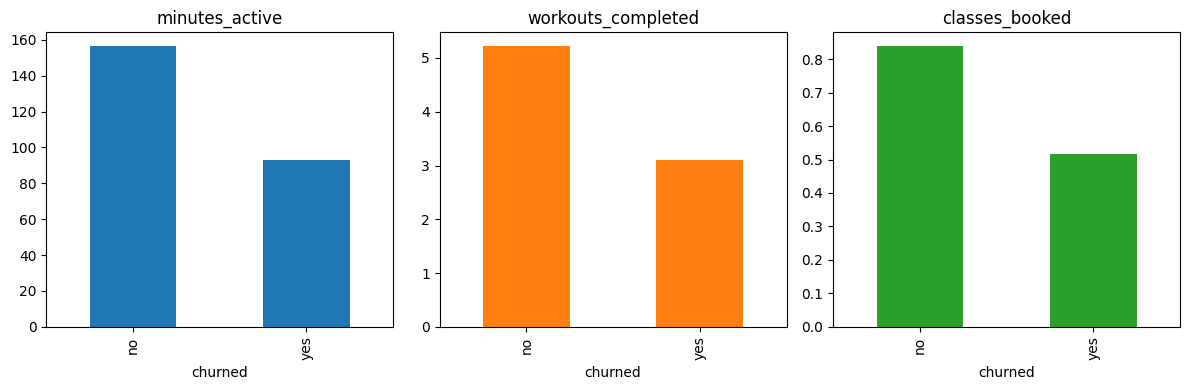

In [ ]:
df = usage.merge(subs[["customer_id", "churned"]], on="customer_id")

# moyenne par groupe
comparaison = df.groupby("churned")[["minutes_active", "workouts_completed", "classes_booked"]].mean()
print(comparaison)

# graphique
comparaison.plot(kind="bar", subplots=True, layout=(1,3), figsize=(12,4), legend=False)
plt.tight_layout()
plt.show()


- **Cet écart s’observe dès le premier mois,** ce qui suppose un problème d’intégration de l’application dans le quotidien de certains clients et non pas de lassitude de Peloton.
<img src="Cohorte.png" width="700">

- Le motif de résiliation le plus fréquent étant le sous-usage (« pas assez utilisé »), le problème d’intégration soulevé est confirmé, les clients partis n’avaient pas intégré l’app à leur routine.
<img src="Raison.png" width="700">


**Quand ?**

* Les 3 premiers mois sont cruciaux pour inscrire Peloton dans la vie quotidienne des nouveaux clients car 40% de ceux qui résilient leur abonnement le font durant cette période des 3 premiers mois.
<img src="Duree_de_vie.png" width="700">


* Entre la fin de l’année 2024 et le début de l'année 2025 le nombre de résiliation n'a eu de cesse d'augmenter et celui des inscriptions de baisser puis de stagner (2 premier mois de 2025) durant la meilleure période pour les applications fitness. Lors des premiers mois de l’année, les potentiels clients ainsi que ceux acquis établissent de nouvelles résolutions pour l'année dont le fait de prendre soin d'eux. Pourtant c'est à cette période où Peloton subit un crash. Pour le début de l'année 2026, il faut que les clients déjà engagés perçoivent la valeur de l'application Peloton dans leur vie. Et établir une meilleure présentation de notre offre au potentiel client qui doit choisir entre Peloton et toutes les autres applications pour accomplir ses objectifs.

<img src="Solde.png" width="700">

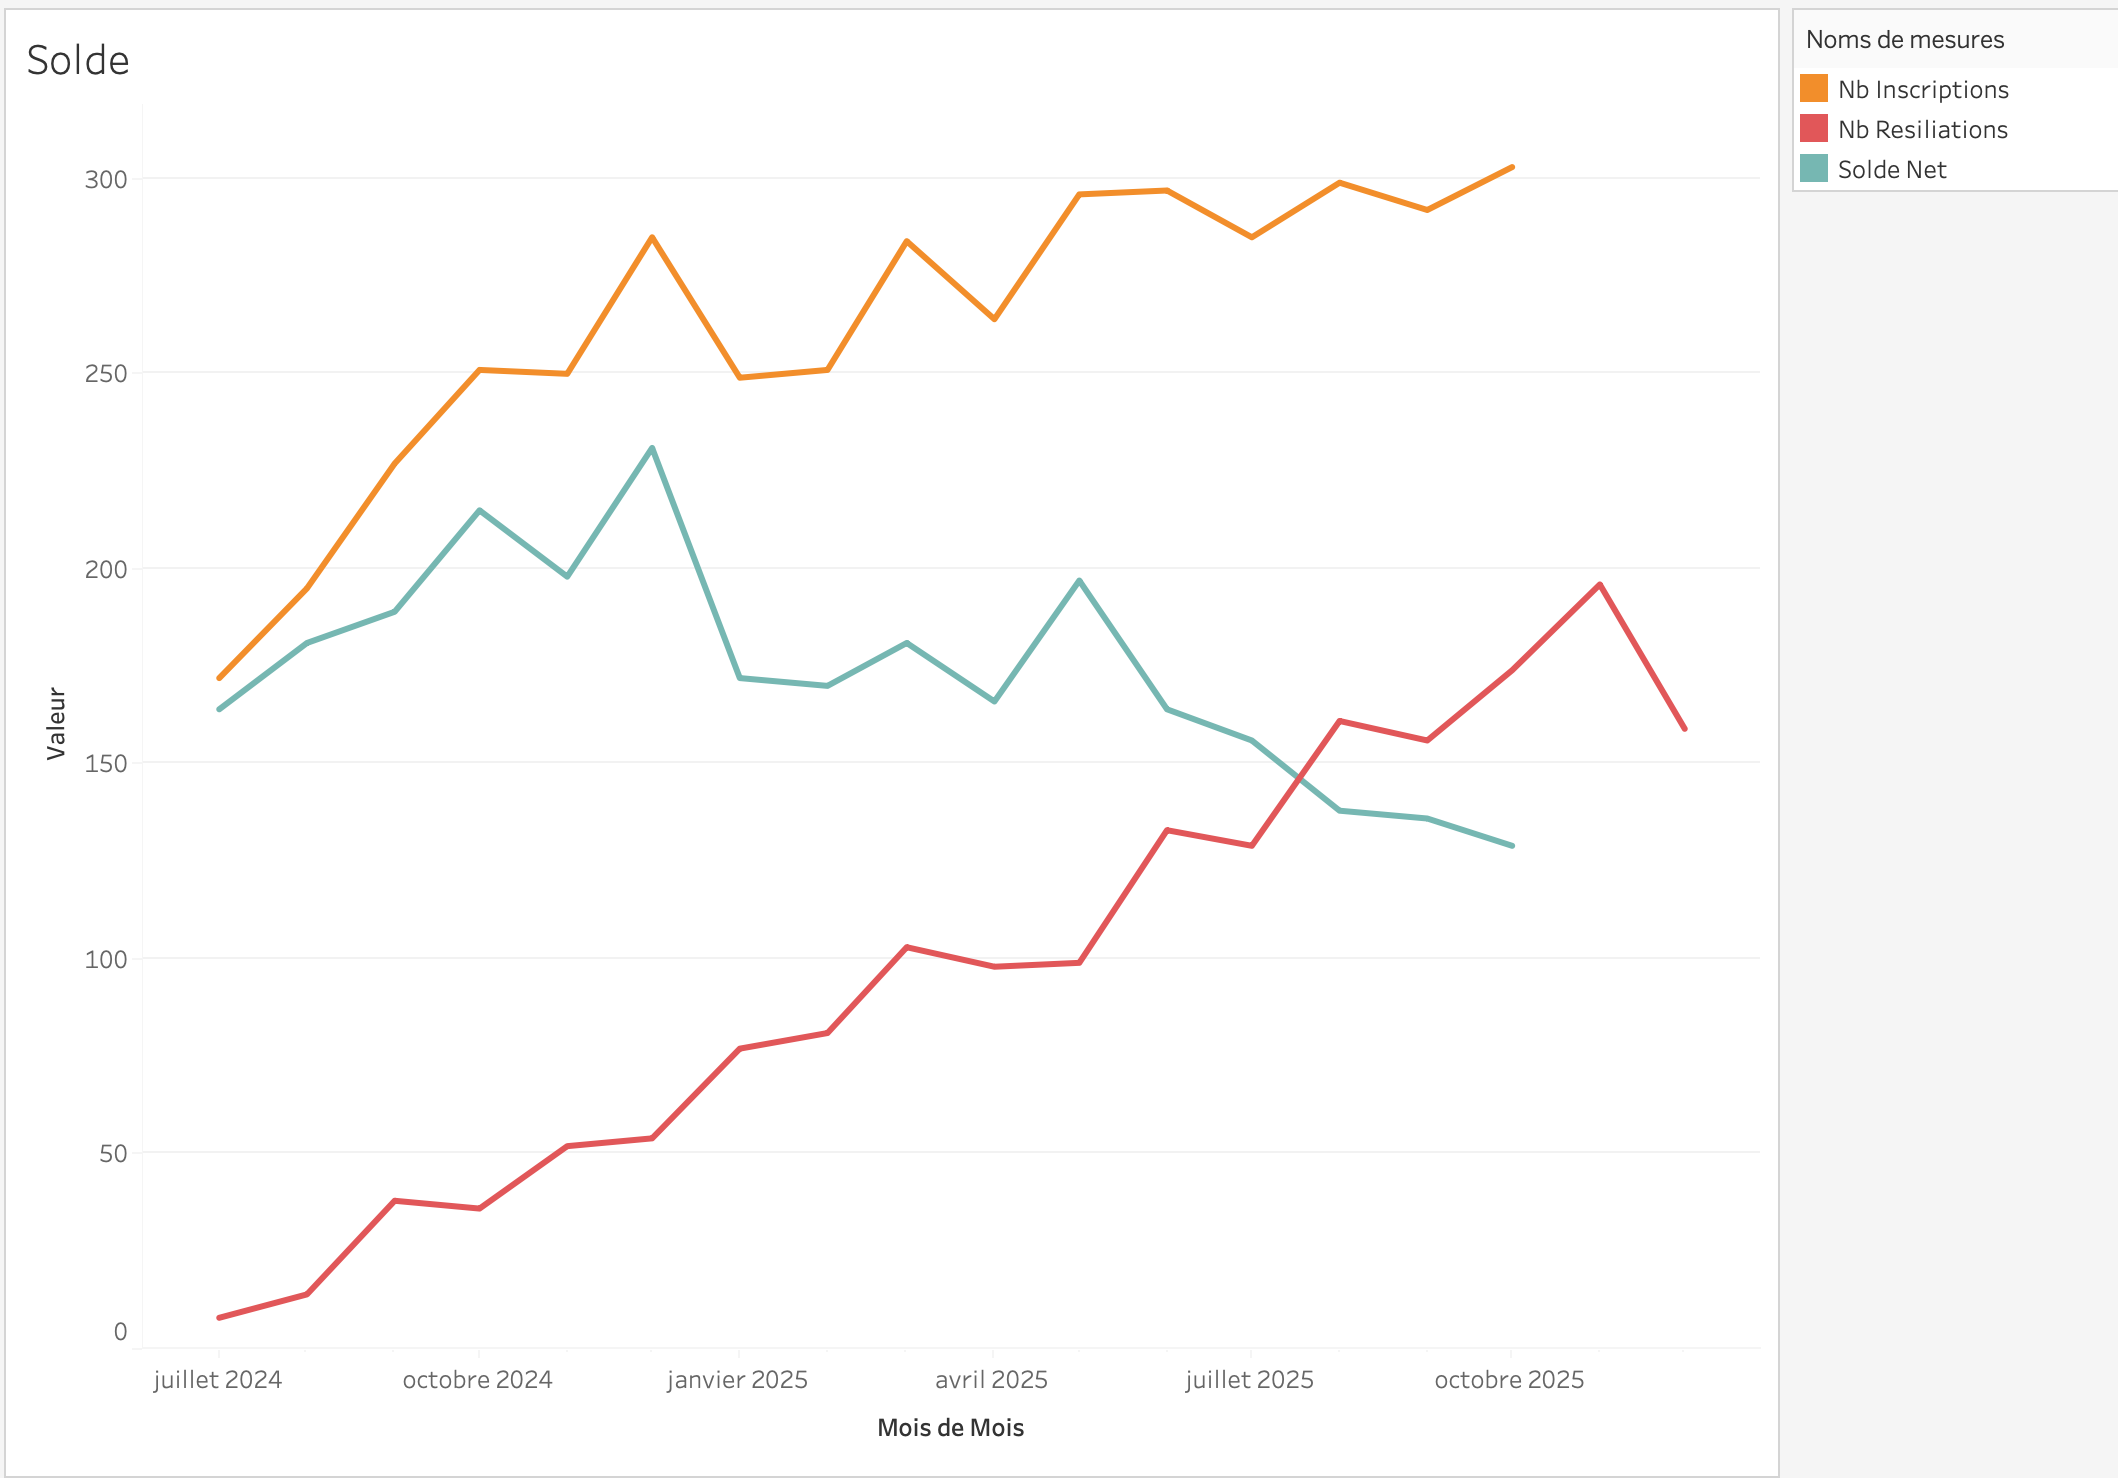

In [16]:
from IPython.display import Image
Image("Solde.png", width=900)

# Modèle de prédiction du churn

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving subscriptions_clean.csv to subscriptions_clean (1).csv
Saving usage_clean.csv to usage_clean (1).csv


In [ ]:
import pandas as pd

subs_c = pd.read_csv("subscriptions_clean.csv")
usage_c = pd.read_csv("usage_clean.csv")

print(subs_c.shape)
print(usage_c.shape)

(4200, 11)
(30525, 6)


## Préparation de la table

In [ ]:
# regroupement de l'activité de chaque clients en un seul enregistrement
usage_resume = usage_c.groupby("customer_id").agg(
    minutes_moy   = ("minutes_active", "mean"),
    seances_moy   = ("workouts_completed", "mean"),
    cours_moy     = ("classes_booked", "mean"),
    tickets_total = ("support_tickets", "sum"),
    nb_mois_actif = ("month", "count")
).reset_index()
usage_resume.shape

(4200, 6)

In [ ]:
# jointure de la table Subsriptions et Usage afin d'établir le profil complet de chaque clients en une seul table
df_model = subs_c.merge(usage_resume, on="customer_id", how="left")
print(df_model.shape)

(4200, 16)


## Séparer cible et indices

In [ ]:
# la cible : 1 si churné, 0 sinon
y = (df_model["churned"] == "yes").astype(int)

# les features : exclusion de ce qui aiderait le modèle
colonnes_a_exclure = ["churned", "churn_date", "cancel_reason", "customer_id", "signup_date", "nb_mois_actif"]
X = df_model.drop(columns=colonnes_a_exclure)

print(X.shape)
print(X.columns.tolist())

(4200, 10)
['plan_type', 'plan_tier', 'monthly_price', 'acquisition_channel', 'primary_device', 'age_group', 'minutes_moy', 'seances_moy', 'cours_moy', 'tickets_total']


## Transformer le texte en nombres

In [ ]:
# encodage des variables texte
X_encoded = pd.get_dummies(X, drop_first=True)
print(X_encoded.shape)
print(X_encoded.columns.tolist())

(4200, 18)
['monthly_price', 'minutes_moy', 'seances_moy', 'cours_moy', 'tickets_total', 'plan_type_monthly', 'plan_tier_plus', 'plan_tier_premium', 'acquisition_channel_paid_social', 'acquisition_channel_partner', 'acquisition_channel_promo_offer', 'acquisition_channel_referral', 'primary_device_ios', 'primary_device_web', 'age_group_25-34', 'age_group_35-44', 'age_group_45-54', 'age_group_55+']


In [ ]:
# vérification de valeurs manquantes
X_encoded.isnull().sum()

,0
monthly_price,0
minutes_moy,9
seances_moy,0
cours_moy,0
tickets_total,0
plan_type_monthly,0
plan_tier_plus,0
plan_tier_premium,0
acquisition_channel_paid_social,0
acquisition_channel_partner,0


In [ ]:
X_encoded = X_encoded.fillna(X_encoded.median())        # valeur manquantes remplacer par la médiane de sa feature

# vérification : plus aucun NaN
print(X_encoded.isnull().sum().sum())

0


## Couper en entraînement / test

In [ ]:
# séparer entraînement(80%) et test (20%)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(    # découpage des données en deux automatiquement
    X_encoded, y,
    test_size=0.2,                                      # 20% pour le test
    random_state=42,                                    # hasard du découpage
    stratify=y                                          # proportion de churn (42%) respecter lors de l’entraînement et du test
)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)

Entraînement : (3360, 18)
Test : (840, 18)


## Entraîner

On utilise une régression logistique, qui est un modèle de classification permettant de prédire une catégorie afin de savoir si le client va résilier son abonnement ou non.

In [ ]:
from sklearn.linear_model import LogisticRegression     # modèle de machine learning de régression logistique
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()                               # met toutes les variables sur la même échelle
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modele = LogisticRegression(max_iter=1000)              # création du modèle et 1 000 essais d'itération accordé
modele.fit(X_train_scaled, y_train)                            # entrainement

LogisticRegression(max_iter=1000)

## Évaluer

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

probas = modele.predict_proba(X_test_scaled)[:, 1]
seuil = 0.5
y_pred_seuil = (probas >= seuil).astype(int)

print("Exactitude :", round(accuracy_score(y_test, y_pred_seuil) * 100, 1), "%")
print()
print(classification_report(y_test, y_pred_seuil))

Exactitude : 68.7 %

              precision    recall  f1-score   support

           0       0.72      0.76      0.74       486
           1       0.64      0.59      0.61       354

    accuracy                           0.69       840
   macro avg       0.68      0.67      0.68       840
weighted avg       0.68      0.69      0.69       840



Le modèle atteint 69% d’exactitude. Il repère 6 churners sur 10 (59%) avant qu’ils partent (recall), et quand il en signale un, sur 10 clients traiter (notification, coaching...), 6 seraient vraiment partis (64%, precision).

C’est exploitable pour cibler des actions de rétention : en concentrant l’effort sur les clients identifiés, on est bien plus efficace qu’un ciblage aléatoire. Le coût d’une fausse alerte (36% de relance inutile) étant faible face au gain d’un client retenu, le modèle apporte une réelle plus value.

On peut également ajuster le seuil de décision selon qu’on privilégie attraper plus de churners (recall) ou limiter les fausses alertes (precision).

## Interpréter

In [ ]:
# Le modèle juge les variables les plus importantes dans la détermination des clients qui vont résilier leur contrat

coefs = pd.DataFrame({
    "variable": X_train.columns,
    "poids": modele.coef_[0]                # poids appris pour chaque variable
}).sort_values("poids", ascending=False)    # poids positif = augmente le risque de churn ; poids négatif = le réduit

print(coefs)                        # ranger dans l'orde suivant : des variables qui poussent le client a partir à celles qui les fidélisent.

                           variable     poids
5                 plan_type_monthly  0.584355
10  acquisition_channel_promo_offer  0.161460
1                       minutes_moy  0.150224
4                     tickets_total  0.059020
0                     monthly_price  0.047409
15                  age_group_35-44  0.029023
9       acquisition_channel_partner  0.020214
16                  age_group_45-54  0.017126
14                  age_group_25-34  0.001666
3                         cours_moy -0.002133
11     acquisition_channel_referral -0.002312
8   acquisition_channel_paid_social -0.042648
17                    age_group_55+ -0.048090
7                 plan_tier_premium -0.048438
6                    plan_tier_plus -0.061088
13               primary_device_web -0.069682
12               primary_device_ios -0.070351
2                       seances_moy -0.992475


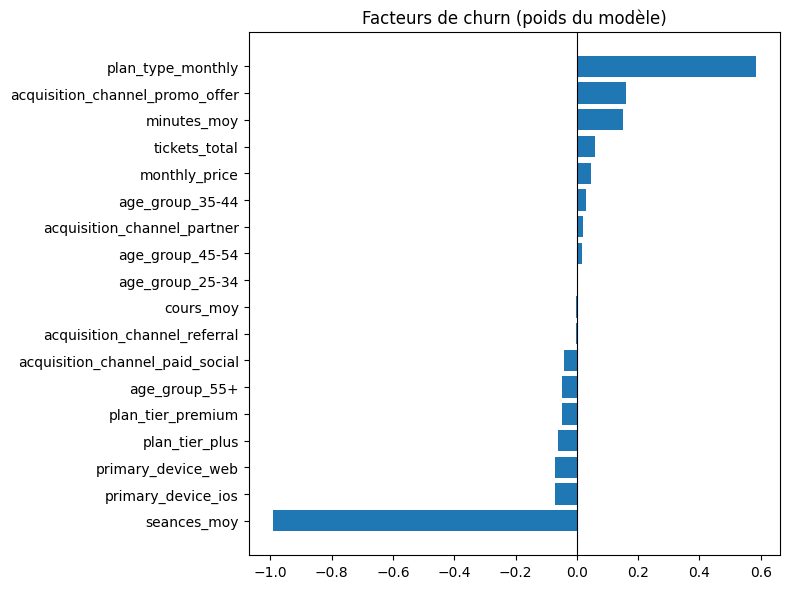

In [ ]:
# Visualisation du poids de chaque variable
import matplotlib.pyplot as plt

coefs_tries = coefs.sort_values("poids")
plt.figure(figsize=(8, 6))
plt.barh(coefs_tries["variable"], coefs_tries["poids"])
plt.title("Facteurs de churn (poids du modèle)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

Le modèle confirme les facteurs identifiés dans l’analyse (forfait mensuel, canal promo, engagement) et apporte une précision : c’est la régularité des séances, plus que le temps passé, qui protège le mieux du risque de churn.

# Conclusions

<img src="Dashboard.png" width="700">

**Recommandations**

- Réallouer le budget promo vers un système de parrainage où le parrain a par exemple 1 mois offert ou une réduction sur l’année sur son abonnement.
- Surveillance de l’activité des nouveaux membres et déclencher une action de réengagement (notification, coaching, rappel d’objectif) pour ceux qui restent sous un seuil d’activité inférieur à la moyenne globale dès les premières semaines.
- Afin de maximiser l’efficacité de l'offre de parrainage, elle ne doit être débloquée qu'au bout de 3 à 6 mois d'ancienneté avec l’atteinte de l'objectif de séances que le client s’est fixé lors de son inscription. Permettant ainsi d'augmenter le sentiment d'accomplissement du client et son engagement envers Peloton. Ayant perçu la valeur concrète de l'application à long terme, ils seront de bons ambassadeurs de Peloton auprès de leur entourage.
- Encourager les nouveaux clients et ceux qui renouvellent leur abonnement mensuel à choisir l’abonnement annuel.

**Limites**

- Les motivations d’achat (compulsif, besoin) sont des hypothèses émises, pas des mesures vérifiables.
- L’analyse usage est en moyenne mensuelle permettant de neutraliser une potentielle erreur due à la durée de l’abonnement.
- Une part notable des clients partis (environ 380) n’ont renseigné aucun motif de résiliation, laissant une zone d’ombre sur une partie des départs.